# K-means: segmentación de clientes de Andina Retail Corp

**Técnica seleccionada en la Fase 1 (sección 4.2).** Agrupa a los 120 clientes por su comportamiento de compra y guarda el grupo en `Dim_Cliente.segmento_cluster`, para filtrar los KPIs comerciales en el cubo y en Power BI.

**Cómo correrlo:** de principio a fin (*Run All*). Por defecto lee `data/sample/` (no necesita SQL Server). Para leer la BD: variable de entorno `FUENTE=bd`.

El notebook sigue las fases del proceso KDD (Clase 13.2, UIA4): selección → preparación y transformación → minería → evaluación e interpretación → difusión. K-means (Clase 14.3.2) repite asignar cada cliente al centroide más cercano y mover cada centroide a la media de su grupo, hasta que no cambian; minimiza la suma de distancias cuadráticas.

Las celdas marcadas con **🟨 DECISIÓN DEL EQUIPO** son las que les toca revisar y justificar en el informe. Todo lo demás es mecánico.

## KDD 1. Selección de datos
Tablas del DW (o su extracto) según el contrato.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from datos import cargar, SALIDA

SEMILLA = 42                      # fija: los resultados se reproducen igual en cualquier máquina
FIGURAS = SALIDA / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", "{:,.2f}".format)

FUENTE = os.getenv("FUENTE", "muestra")  # "bd" = SQL Server (AndinaRetailDW); "muestra" = data/sample
t = cargar(FUENTE)
print("Fuente:", FUENTE)
{n: len(df) for n, df in t.items()}

Fuente: bd


{'Dim_Mes': 12,
 'Dim_Tiempo': 366,
 'Dim_Cliente': 120,
 'Dim_Producto': 20,
 'Dim_Canal': 2,
 'Dim_Vendedor': 5,
 'Dim_Region': 4,
 'Hecho_Ventas': 850,
 'Hecho_Finanzas_Mensual': 12,
 'Hecho_Trafico_Web': 120}

## KDD 2. Preparación y transformación: variables por cliente
Las siete de la Fase 1: venta total, número de órdenes, ticket promedio, % de compras en e-commerce, número de categorías compradas, visitas web y tasa de conversión.

In [2]:
v = (t["Hecho_Ventas"]
     .merge(t["Dim_Canal"], on="canal_key")
     .merge(t["Dim_Producto"], on="producto_key"))

compras = v.groupby("cliente_key").agg(
    venta_total=("total", "sum"),
    num_ordenes=("orden_id", "nunique"),
    num_categorias=("categoria", "nunique"),
    ordenes_ecommerce=("canal", lambda s: (s == "E-commerce").sum()),
)
compras["ticket_promedio"] = compras["venta_total"] / compras["num_ordenes"]
compras["pct_ecommerce"] = 100 * compras["ordenes_ecommerce"] / compras["num_ordenes"]

web = t["Hecho_Trafico_Web"].set_index("cliente_key")
web["tasa_conversion"] = 100 * web["conversiones_web"] / web["visitas_web"].replace(0, np.nan)

clientes = (t["Dim_Cliente"].set_index("cliente_key")[["cliente_id", "segmento"]]
            .join(compras).join(web[["visitas_web", "tasa_conversion"]]))
clientes = clientes.fillna({"venta_total": 0, "num_ordenes": 0, "num_categorias": 0,
                            "ticket_promedio": 0, "pct_ecommerce": 0, "tasa_conversion": 0})
assert len(clientes) == len(t["Dim_Cliente"]), "debe haber una fila por cliente"
clientes.describe().T

,count,mean,std,min,25%,50%,75%,max
venta_total,120.00,"5,875.95","3,084.63",401.02,"3,600.61","5,584.16","7,648.72","16,897.11"
num_ordenes,120.00,7.08,2.59,2.00,5.75,7.00,9.00,15.00
num_categorias,120.00,3.33,0.75,1.00,3.00,3.00,4.00,4.00
ordenes_ecommerce,120.00,2.94,1.76,0.00,2.00,3.00,4.00,8.00
ticket_promedio,120.00,830.04,355.73,200.51,628.27,804.85,988.47,"2,120.71"
pct_ecommerce,120.00,40.45,18.48,0.00,28.57,42.86,50.00,100.00
visitas_web,120.00,211.45,119.92,7.00,114.50,233.00,304.25,395.00
tasa_conversion,120.00,8.50,5.10,0.00,4.76,7.85,12.61,17.77


### 🟨 DECISIÓN DEL EQUIPO: variables del modelo
Por defecto, las siete de la Fase 1. Si quitan alguna (por ejemplo, por estar muy correlacionada con otra), justifíquenlo en el informe con la matriz de abajo.

In [3]:
VARIABLES = ["venta_total", "num_ordenes", "ticket_promedio", "pct_ecommerce",
             "num_categorias", "visitas_web", "tasa_conversion"]
clientes[VARIABLES].corr().round(2)

,venta_total,num_ordenes,ticket_promedio,pct_ecommerce,num_categorias,visitas_web,tasa_conversion
venta_total,1.00,0.71,0.63,0.24,0.43,0.00,0.08
num_ordenes,0.71,1.00,-0.00,0.16,0.70,0.08,0.05
ticket_promedio,0.63,-0.00,1.00,0.35,-0.13,-0.07,0.04
pct_ecommerce,0.24,0.16,0.35,1.00,0.06,0.07,-0.02
num_categorias,0.43,0.70,-0.13,0.06,1.00,-0.11,-0.02
visitas_web,0.00,0.08,-0.07,0.07,-0.11,1.00,0.18
tasa_conversion,0.08,0.05,0.04,-0.02,-0.02,0.18,1.00


### Transformación: estandarización
Las variables mezclan dólares, conteos y porcentajes; sin escalar, la venta total dominaría la distancia.

In [4]:
X = StandardScaler().fit_transform(clientes[VARIABLES])
X.shape

(120, 7)

## KDD 3. Minería de datos: elección de k con codo y silueta (k = 3 a 6, Fase 1)

,inercia,silueta
k,,
3,563.56,0.19
4,491.69,0.17
5,453.35,0.15
6,424.61,0.15


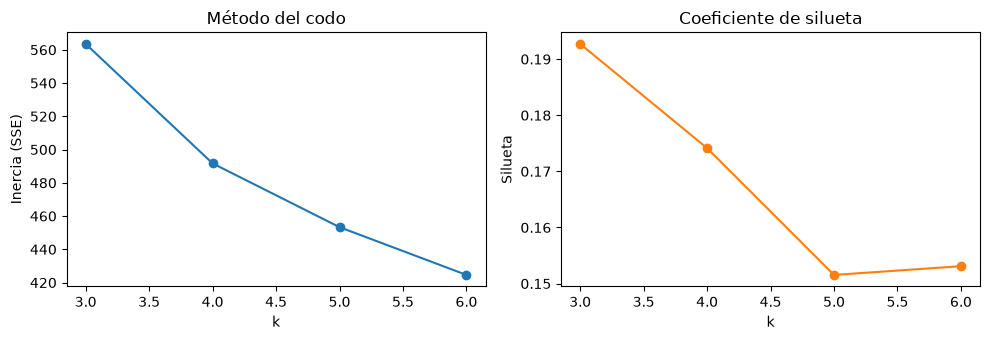

In [5]:
K_RANGO = range(3, 7)
evaluacion = []
for k in K_RANGO:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEMILLA).fit(X)
    evaluacion.append({"k": k, "inercia": km.inertia_, "silueta": silhouette_score(X, km.labels_)})
evaluacion = pd.DataFrame(evaluacion).set_index("k")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
evaluacion["inercia"].plot(ax=ax[0], marker="o", title="Método del codo", ylabel="Inercia (SSE)")
evaluacion["silueta"].plot(ax=ax[1], marker="o", title="Coeficiente de silueta", ylabel="Silueta", color="C1")
fig.tight_layout(); fig.savefig(FIGURAS / "eleccion_k.png", dpi=150)
evaluacion

### 🟨 DECISIÓN DEL EQUIPO: k
Por defecto se toma el k con mayor silueta. Si el codo sugiere otro valor, o si los grupos de otro k se describen mejor con una frase (criterio de la Fase 1), cambien `K_ELEGIDO` y expliquen por qué.

In [6]:
K_ELEGIDO = None   # p. ej. 4; None = mejor silueta
k = K_ELEGIDO or int(evaluacion["silueta"].idxmax())
print("k =", k, "| silueta =", round(evaluacion.loc[k, "silueta"], 3))

k = 3 | silueta = 0.193


### Modelo final
Los números de grupo de K-means son arbitrarios; se renumeran 1..k de menor a mayor venta total promedio para que no cambien entre ejecuciones.

In [7]:
km = KMeans(n_clusters=k, n_init=20, random_state=SEMILLA).fit(X)
orden = pd.Series(clientes["venta_total"].values).groupby(km.labels_).mean().sort_values().index
renumera = {viejo: nuevo for nuevo, viejo in enumerate(orden, start=1)}
clientes["segmento_cluster"] = [renumera[l] for l in km.labels_]
assert clientes["segmento_cluster"].notna().all() and clientes.index.is_unique  # un solo grupo por cliente
clientes["segmento_cluster"].value_counts().sort_index().rename("clientes")

segmento_cluster
1    44
2    19
3    57
Name: clientes, dtype: int64

## KDD 4. Evaluación e interpretación: perfil de cada grupo

In [8]:
perfil = clientes.groupby("segmento_cluster")[VARIABLES].mean()
perfil.insert(0, "clientes", clientes["segmento_cluster"].value_counts().sort_index())
perfil

,clientes,venta_total,num_ordenes,ticket_promedio,pct_ecommerce,num_categorias,visitas_web,tasa_conversion
segmento_cluster,,,,,,,,
1,44,"3,233.89",5.57,566.17,28.44,3.05,217.93,8.44
2,19,"6,192.78",4.79,"1,314.80",56.01,2.47,252.79,9.31
3,57,"7,809.82",9.02,872.15,44.53,3.84,192.67,8.27


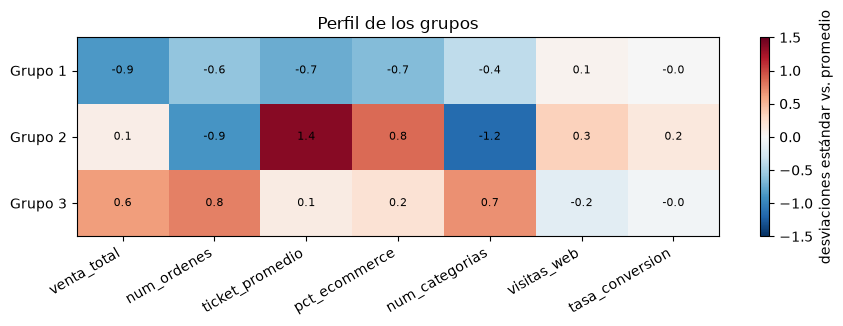

In [9]:
# Perfil relativo al promedio general (z-score medio): ayuda a nombrar cada grupo.
z = pd.DataFrame(X, columns=VARIABLES, index=clientes.index).groupby(clientes["segmento_cluster"]).mean()
fig, ax = plt.subplots(figsize=(9, 0.6 * k + 1.5))
im = ax.imshow(z.values, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(len(VARIABLES)), VARIABLES, rotation=30, ha="right")
ax.set_yticks(range(k), [f"Grupo {g}" for g in z.index])
for i in range(k):
    for j in range(len(VARIABLES)):
        ax.text(j, i, f"{z.values[i, j]:.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, label="desviaciones estándar vs. promedio"); ax.set_title("Perfil de los grupos")
fig.tight_layout(); fig.savefig(FIGURAS / "perfil_grupos.png", dpi=150)

In [10]:
# ¿Los grupos repiten el Segmento del Excel o aportan algo nuevo?
pd.crosstab(clientes["segmento_cluster"], clientes["segmento"], margins=True)

segmento,Consumidor,Corporativo,Pyme,All
segmento_cluster,,,,
1,18,10,16,44
2,6,7,6,19
3,18,16,23,57
All,42,33,45,120


### 🟨 DECISIÓN DEL EQUIPO: nombre e interpretación de cada grupo
Una frase por grupo, a partir del perfil (Fase 1: "un grupo es útil si se puede describir con una frase"). Estos nombres van al informe y a Power BI. Si ningún k da grupos interpretables, el plan B de la Fase 1 es usar los tres segmentos del Excel.

In [11]:
NOMBRES = {1: "Compra poco y en tienda",
           2: "Ticket alto y en línea",
           3: "Frecuentes y de mayor gasto"}
perfil.insert(0, "nombre", pd.Series(NOMBRES))
perfil

,nombre,clientes,venta_total,num_ordenes,ticket_promedio,pct_ecommerce,num_categorias,visitas_web,tasa_conversion
segmento_cluster,,,,,,,,,
1,Compra poco y en tienda,44,"3,233.89",5.57,566.17,28.44,3.05,217.93,8.44
2,Ticket alto y en línea,19,"6,192.78",4.79,"1,314.80",56.01,2.47,252.79,9.31
3,Frecuentes y de mayor gasto,57,"7,809.82",9.02,872.15,44.53,3.84,192.67,8.27


## KDD 5. Difusión y uso: llevar el segmento al DW
`segmentos_cliente.csv` es la entrada que el ETL usa para llenar `Dim_Cliente.segmento_cluster`. Después de correr este notebook:

```
python -m etl.run_etl
```
Eso recarga la BD y `data/sample/` con el segmento, y el cubo y Power BI ya lo pueden usar como filtro.

In [12]:
SALIDA.mkdir(parents=True, exist_ok=True)
clientes[["cliente_id", "segmento_cluster"]].to_csv(SALIDA / "segmentos_cliente.csv", index=False, encoding="utf-8-sig")
perfil.reset_index().to_csv(SALIDA / "perfil_segmentos.csv", index=False, encoding="utf-8-sig")
evaluacion.reset_index().to_csv(SALIDA / "evaluacion_k.csv", index=False, encoding="utf-8-sig")
sorted(p.name for p in SALIDA.rglob("*") if p.is_file())

['eleccion_k.png',
 'evaluacion_k.csv',
 'perfil_grupos.png',
 'perfil_segmentos.csv',
 'segmentos_cliente.csv']